# Évaluation des modèles de vision par ordinateur
## Classification · Détection d'objets · Segmentation sémantique · Segmentation d'instances

Ce notebook accompagne la présentation. Il contient :
- une **partie pédagogique sur les trois types de classification** (exemples chiffrés illustratifs, sans entraînement d'un classifieur) ;
- une **expérience sur COCO val2017** pour la détection et les deux types de segmentation, avec 50 images par défaut et des modèles pré-entraînés de `torchvision`.

| Section | Tâche | Modèle / données | Métriques principales |
|---|---|---|---|
| 0 | Setup et données | COCO val2017 | - |
| 1 | Métriques de base | - | IoU, Précision, Rappel, F1, Dice |
| 2 | Classification d'images | Exemples illustratifs | Accuracy, précision, rappel, F1, ROC-AUC, Top-k, Hamming loss |
| 3 | Détection d'objets | Faster R-CNN | AP, mAP@0.5, mAP@[.5:.95], AP par taille, courbe PR, F1-confiance |
| 4 | Segmentation sémantique | DeepLabV3 | Pixel accuracy, IoU par classe, mIoU, Dice, matrice de confusion |
| 5 | Segmentation d'instances | Mask R-CNN | Mask AP, comparaison box AP / mask AP |
| 6 | Synthèse | - | Tableau comparatif, analyse d'erreurs |

**Important :** les trois exemples de classification sont construits pour illustrer le calcul des métriques. Ils ne représentent pas les performances d'un modèle entraîné. Les expériences réelles sur COCO concernent la détection et les deux segmentations.

**Conseil :** sur Google Colab, activez le GPU (*Exécution > Modifier le type d'exécution > GPU*). Sur CPU, comptez une dizaine de minutes pour 50 images.

---
# Section 0 : Setup et données

In [1]:
!pip install -q pycocotools

In [2]:
import os, json, random, zipfile, urllib.request
from collections import defaultdict

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as patches
from PIL import Image

import torch
import torch.nn.functional as F
import torchvision
from torchvision.ops import box_iou
from torchvision.transforms.functional import to_tensor

from pycocotools.coco import COCO
from pycocotools.cocoeval import COCOeval
import pycocotools.mask as mask_util

SEED = 0
N_IMAGES = 50          # augmenter pour des résultats plus stables (ex. 200)
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
DATA_DIR = "data"
os.makedirs(f"{DATA_DIR}/images", exist_ok=True)

print("Device :", DEVICE, "| torch", torch.__version__, "| torchvision", torchvision.__version__)

Device : cuda | torch 2.14.1+cu130 | torchvision 0.29.1+cu130


### Données : sous-ensemble de COCO val2017
On télécharge uniquement le fichier d'annotations `instances_val2017.json` puis `N_IMAGES` images tirées au hasard (graine fixée pour la reproductibilité).
Ces annotations (boîtes + masques d'instances) servent de **vérité terrain** pour les trois tâches.

In [3]:
ANN_ZIP = f"{DATA_DIR}/annotations_trainval2017.zip"
ANN_FILE = f"{DATA_DIR}/annotations/instances_val2017.json"

if not os.path.exists(ANN_FILE):
    if not os.path.exists(ANN_ZIP):
        print("Téléchargement des annotations (~240 Mo)...")
        urllib.request.urlretrieve("http://images.cocodataset.org/annotations/annotations_trainval2017.zip", ANN_ZIP)
    with zipfile.ZipFile(ANN_ZIP) as z:
        z.extract("annotations/instances_val2017.json", DATA_DIR)

coco = COCO(ANN_FILE)

# Images ayant au moins une annotation non "crowd"
rng = random.Random(SEED)
candidates = [i for i in sorted(coco.getImgIds())
              if any(a["iscrowd"] == 0 for a in coco.loadAnns(coco.getAnnIds(imgIds=i)))]
if N_IMAGES > len(candidates):
    raise ValueError(f"N_IMAGES={N_IMAGES} dépasse le nombre d'images disponibles ({len(candidates)}).")
img_ids = sorted(rng.sample(candidates, N_IMAGES))


def img_path(i):
    return f"{DATA_DIR}/images/{i:012d}.jpg"


def load_img(i):
    return Image.open(img_path(i)).convert("RGB")


for i in img_ids:
    if not os.path.exists(img_path(i)):
        urllib.request.urlretrieve(f"http://images.cocodataset.org/val2017/{i:012d}.jpg", img_path(i))

# Vérité terrain indexée par (image, classe) et par image (objets non "crowd")
gt_by = defaultdict(list)
gt_img = defaultdict(list)
for a in coco.loadAnns(coco.getAnnIds(imgIds=img_ids)):
    if a["iscrowd"] == 0:
        gt_by[(a["image_id"], a["category_id"])].append(a)
        gt_img[a["image_id"]].append(a)

print(f"{len(img_ids)} images, {sum(len(v) for v in gt_img.values())} objets annotés")

Téléchargement des annotations (~240 Mo)...
loading annotations into memory...
Done (t=0.50s)
creating index...
index created!
50 images, 339 objets annotés


---
# Section 1 : Métriques de base

Pour une prédiction $P$ et une vérité terrain $G$ (boîtes ou masques) :

$$\text{IoU}(P,G)=\frac{|P\cap G|}{|P\cup G|}\qquad
\text{Dice}(P,G)=\frac{2|P\cap G|}{|P|+|G|}=\frac{2\,\text{IoU}}{1+\text{IoU}}$$

$$\text{Précision}=\frac{TP}{TP+FP}\qquad \text{Rappel}=\frac{TP}{TP+FN}\qquad F1=\frac{2PR}{P+R}$$

Pour la **détection** et la **segmentation d'instances**, une prédiction est un TP si son IoU avec un objet non encore apparié dépasse un seuil (0.5 par exemple) et si la classe est correcte.
Pour la **segmentation sémantique**, TP/FP/FN se comptent **par pixel**.

In [4]:
def box_iou_np(a, b):
    """IoU entre deux ensembles de boîtes (xyxy) -> matrice (N, M)."""
    a = torch.tensor(np.asarray(a, dtype=np.float32).reshape(-1, 4))
    b = torch.tensor(np.asarray(b, dtype=np.float32).reshape(-1, 4))
    return box_iou(a, b).numpy()


def mask_iou_np(m1, m2):
    """IoU entre deux masques binaires."""
    m1, m2 = m1.astype(bool), m2.astype(bool)
    union = (m1 | m2).sum()
    return float((m1 & m2).sum() / union) if union else 0.0


def dice_np(m1, m2):
    m1, m2 = m1.astype(bool), m2.astype(bool)
    s = m1.sum() + m2.sum()
    return float(2 * (m1 & m2).sum() / s) if s else 0.0


def prf(tp, fp, fn):
    p = tp / (tp + fp) if tp + fp else 0.0
    r = tp / (tp + fn) if tp + fn else 0.0
    f1 = 2 * p * r / (p + r) if p + r else 0.0
    return p, r, f1

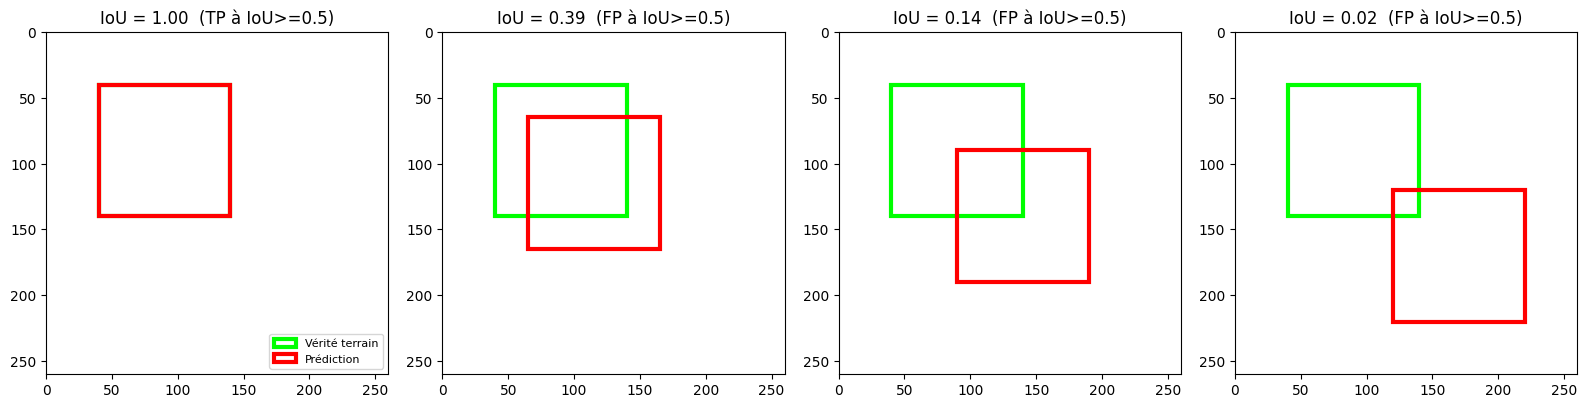

In [5]:
# Illustration : même boîte de référence, prédictions de plus en plus décalées
gt_box = [40, 40, 140, 140]
shifts = [0, 25, 50, 80]
fig, axes = plt.subplots(1, len(shifts), figsize=(4 * len(shifts), 4))
for ax, s in zip(axes, shifts):
    pred = [40 + s, 40 + s, 140 + s, 140 + s]
    iou = box_iou_np([pred], [gt_box])[0, 0]
    ax.add_patch(patches.Rectangle(gt_box[:2], 100, 100, fill=False, ec="lime", lw=3, label="Vérité terrain"))
    ax.add_patch(patches.Rectangle(pred[:2], 100, 100, fill=False, ec="red", lw=3, label="Prédiction"))
    ax.set_xlim(0, 260); ax.set_ylim(260, 0); ax.set_aspect("equal")
    ax.set_title(f"IoU = {iou:.2f}  ({'TP' if iou >= 0.5 else 'FP'} à IoU>=0.5)")
axes[0].legend(loc="lower right", fontsize=8)
plt.tight_layout(); plt.show()

---
# Section 2 : Classification d'images

La classification prédit une ou plusieurs **étiquettes pour une image entière**. Contrairement à la détection et à la segmentation, elle ne fournit pas la position des objets.

On distingue trois cas :
1. **Binaire** : une seule question, avec deux réponses possibles (ex. : présence ou absence d'un zèbre).
2. **Multi-classe** : une seule classe parmi plusieurs classes exclusives (ex. : chat, chien ou oiseau).
3. **Multi-label** : plusieurs classes peuvent être présentes simultanément (ex. : personne, voiture et vélo).

Les exemples ci-dessous utilisent des valeurs illustratives afin de montrer comment calculer et interpréter les métriques. Ils ne correspondent pas à une inférence de modèle.

## 2.1 Classification binaire

Exemple : détecter si une image contient un zèbre (`1`) ou non (`0`). La matrice de confusion contient :
- **TP** : zèbre correctement détecté ;
- **FN** : zèbre manqué ;
- **FP** : fausse alerte ;
- **TN** : absence correctement reconnue.

On calcule l'accuracy, la précision, le rappel, la spécificité et le F1-score.

In [6]:
# Exemple illustratif : 100 images, dont 50 contiennent un zèbre.
# 40 TP, 10 FN, 5 FP et 45 TN.
y_true_bin = np.array([1] * 50 + [0] * 50)
y_pred_bin = np.array([1] * 40 + [0] * 10 + [1] * 5 + [0] * 45)

tp = int(np.sum((y_true_bin == 1) & (y_pred_bin == 1)))
fn = int(np.sum((y_true_bin == 1) & (y_pred_bin == 0)))
fp = int(np.sum((y_true_bin == 0) & (y_pred_bin == 1)))
tn = int(np.sum((y_true_bin == 0) & (y_pred_bin == 0)))

accuracy_bin = (tp + tn) / len(y_true_bin)
precision_bin = tp / (tp + fp) if tp + fp else 0
recall_bin = tp / (tp + fn) if tp + fn else 0
specificity_bin = tn / (tn + fp) if tn + fp else 0
f1_bin = (2 * precision_bin * recall_bin / (precision_bin + recall_bin)
          if precision_bin + recall_bin else 0)

cm_bin = pd.DataFrame(
    [[tp, fn], [fp, tn]],
    index=["Réel : zèbre", "Réel : sans zèbre"],
    columns=["Prédit : zèbre", "Prédit : sans zèbre"]
)
display(cm_bin)
display(pd.Series({
    "Accuracy": accuracy_bin,
    "Précision": precision_bin,
    "Rappel / sensibilité": recall_bin,
    "Spécificité": specificity_bin,
    "F1-score": f1_bin
}, name="Valeur").to_frame().round(3))

print("Interprétation : le modèle retrouve 80 % des zèbres (rappel = 0,80).")

,Prédit : zèbre,Prédit : sans zèbre
Réel : zèbre,40,10
Réel : sans zèbre,5,45


,Valeur
Accuracy,0.850
Précision,0.889
Rappel / sensibilité,0.800
Spécificité,0.900
F1-score,0.842


Interprétation : le modèle retrouve 80 % des zèbres (rappel = 0,80).


**À retenir :** la précision répond à « parmi les images prédites positives, combien sont correctes ? ». Le rappel répond à « parmi les images réellement positives, combien ont été retrouvées ? ». Le F1 équilibre les deux. La ROC-AUC évalue le classement des scores pour plusieurs seuils ; elle nécessite les scores/probabilités, pas seulement la matrice de confusion.

## 2.2 Classification multi-classe

Exemple : chaque image contient une seule classe parmi `chat`, `chien` et `oiseau`. La matrice de confusion devient une matrice **N × N**. La diagonale représente les bonnes prédictions ; les autres cases représentent les confusions.

On calcule les métriques pour chaque classe, puis les moyennes **macro**, **micro** ou **pondérée**.

In [7]:
# Lignes = classe réelle ; colonnes = classe prédite.
classes_mc = ["Chat", "Chien", "Oiseau"]
cm_mc = np.array([
    [30, 5, 0],
    [8, 25, 2],
    [1, 4, 25]
], dtype=int)

display(pd.DataFrame(cm_mc, index=classes_mc, columns=classes_mc))

tp_per_class = np.diag(cm_mc).astype(float)
fp_per_class = cm_mc.sum(axis=0) - tp_per_class
fn_per_class = cm_mc.sum(axis=1) - tp_per_class

precision_mc = np.divide(tp_per_class, tp_per_class + fp_per_class,
                         out=np.zeros_like(tp_per_class), where=(tp_per_class + fp_per_class) != 0)
recall_mc = np.divide(tp_per_class, tp_per_class + fn_per_class,
                      out=np.zeros_like(tp_per_class), where=(tp_per_class + fn_per_class) != 0)
f1_mc = np.divide(2 * precision_mc * recall_mc, precision_mc + recall_mc,
                  out=np.zeros_like(tp_per_class), where=(precision_mc + recall_mc) != 0)

per_class_mc = pd.DataFrame({
    "Précision": precision_mc,
    "Rappel": recall_mc,
    "F1": f1_mc
}, index=classes_mc)

accuracy_mc = tp_per_class.sum() / cm_mc.sum()
macro_mc = per_class_mc.mean()
# En classification multi-classe à étiquette unique, micro-F1 = accuracy.
micro_f1_mc = accuracy_mc
weighted_mc = (per_class_mc.mul(cm_mc.sum(axis=1), axis=0).sum()
               / cm_mc.sum(axis=1).sum())

display(per_class_mc.round(3))
display(pd.DataFrame({
    "Accuracy": [accuracy_mc],
    "F1 macro": [macro_mc["F1"]],
    "F1 micro": [micro_f1_mc],
    "F1 pondéré": [weighted_mc["F1"]]
}).round(3))

print("Interprétation : les erreurs hors diagonale montrent notamment des chiens prédits comme des chats.")

,Chat,Chien,Oiseau
Chat,30,5,0
Chien,8,25,2
Oiseau,1,4,25


,Précision,Rappel,F1
Chat,0.769,0.857,0.811
Chien,0.735,0.714,0.725
Oiseau,0.926,0.833,0.877


,Accuracy,F1 macro,F1 micro,F1 pondéré
0,0.8,0.804,0.8,0.801


Interprétation : les erreurs hors diagonale montrent notamment des chiens prédits comme des chats.


**À retenir :** la moyenne **macro** donne le même poids à chaque classe et met en évidence les classes moins bien reconnues. La moyenne **micro** cumule les décisions ; en multi-classe à une seule étiquette, le micro-F1 est égal à l'accuracy. La **Top-k accuracy** est utile lorsque le modèle fournit plusieurs classes candidates : la prédiction est correcte si la vraie classe apparaît parmi les k premières.

## 2.3 Classification multi-label

Une image peut contenir **zéro, une ou plusieurs étiquettes**. Chaque classe est donc évaluée comme une décision binaire indépendante.

Dans l'exemple suivant, les colonnes représentent `personne`, `voiture`, `chien` et `vélo`. Nous avons une étiquette manquée (chien) et une fausse alerte (vélo).

In [8]:
labels_ml = ["Personne", "Voiture", "Chien", "Vélo"]

# 1 = étiquette présente ; 0 = étiquette absente.
y_true_ml = np.array([
    [1, 1, 0, 0],  # Image 1
    [1, 0, 1, 0],  # Image 2
    [0, 1, 0, 0],  # Image 3
    [1, 0, 0, 1],  # Image 4
])
y_pred_ml = np.array([
    [1, 1, 0, 0],  # Image 1 : correcte
    [1, 0, 0, 0],  # Image 2 : chien manqué
    [0, 1, 0, 1],  # Image 3 : vélo en trop
    [1, 0, 0, 1],  # Image 4 : correcte
])

# Exact match : toutes les étiquettes d'une image doivent être correctes.
exact_match = np.all(y_true_ml == y_pred_ml, axis=1).mean()
hamming_loss = np.mean(y_true_ml != y_pred_ml)

tp_ml = np.sum((y_true_ml == 1) & (y_pred_ml == 1), axis=0).astype(float)
fp_ml = np.sum((y_true_ml == 0) & (y_pred_ml == 1), axis=0).astype(float)
fn_ml = np.sum((y_true_ml == 1) & (y_pred_ml == 0), axis=0).astype(float)

precision_ml = np.divide(tp_ml, tp_ml + fp_ml, out=np.zeros_like(tp_ml), where=(tp_ml + fp_ml) != 0)
recall_ml = np.divide(tp_ml, tp_ml + fn_ml, out=np.zeros_like(tp_ml), where=(tp_ml + fn_ml) != 0)
f1_per_label = np.divide(2 * precision_ml * recall_ml, precision_ml + recall_ml,
                         out=np.zeros_like(tp_ml), where=(precision_ml + recall_ml) != 0)

micro_tp, micro_fp, micro_fn = tp_ml.sum(), fp_ml.sum(), fn_ml.sum()
micro_f1_ml = 2 * micro_tp / (2 * micro_tp + micro_fp + micro_fn)
macro_f1_ml = f1_per_label.mean()

display(pd.DataFrame(y_true_ml, columns=labels_ml, index=[f"Image {i}" for i in range(1, 5)]).replace({1: "présent", 0: "absent"}))
display(pd.DataFrame(y_pred_ml, columns=labels_ml, index=[f"Image {i}" for i in range(1, 5)]).replace({1: "prédit", 0: "—"}))
display(pd.DataFrame({
    "F1 par étiquette": f1_per_label
}, index=labels_ml).round(3))
display(pd.Series({
    "Exact match": exact_match,
    "Hamming loss": hamming_loss,
    "F1 micro": micro_f1_ml,
    "F1 macro": macro_f1_ml
}, name="Valeur").to_frame().round(3))

print("Interprétation : exact match = 0,50 car seules 2 images sur 4 ont toutes leurs étiquettes correctes.")

,Personne,Voiture,Chien,Vélo
Image 1,présent,présent,absent,absent
Image 2,présent,absent,présent,absent
Image 3,absent,présent,absent,absent
Image 4,présent,absent,absent,présent


,Personne,Voiture,Chien,Vélo
Image 1,prédit,prédit,—,—
Image 2,prédit,—,—,—
Image 3,—,prédit,—,prédit
Image 4,prédit,—,—,prédit


,F1 par étiquette
Personne,1.000
Voiture,1.000
Chien,0.000
Vélo,0.667


,Valeur
Exact match,0.500
Hamming loss,0.125
F1 micro,0.857
F1 macro,0.667


Interprétation : exact match = 0,50 car seules 2 images sur 4 ont toutes leurs étiquettes correctes.


**À retenir :** l'**exact match** est strict : toutes les étiquettes d'une image doivent être correctes. La **Hamming loss** mesure la proportion de décisions erronées. Le **F1 micro** cumule toutes les étiquettes, tandis que le **F1 macro** calcule d'abord le F1 de chaque étiquette puis en fait la moyenne. Le **mAP** peut aussi être utilisé à partir des scores de confiance, avant d'appliquer un seuil.

---
# Section 3 : Évaluation de la détection d'objets

**Sortie du modèle :** pour chaque objet, une boîte, une classe et un **score de confiance**.

**Protocole d'évaluation (type COCO) :**
1. On trie les prédictions d'une classe par score décroissant.
2. Chaque prédiction est appariée à la vérité terrain non utilisée ayant le meilleur IoU ; c'est un TP si IoU $\geq$ seuil, sinon un FP. Les objets non appariés sont des FN.
3. On trace la **courbe précision-rappel** ; l'**AP** est l'aire sous cette courbe (avec précision interpolée).
4. **mAP** = moyenne de l'AP sur les classes. COCO moyenne en plus sur 10 seuils d'IoU de 0.50 à 0.95 : **mAP@[.5:.95]**.

In [9]:
from torchvision.models.detection import fasterrcnn_resnet50_fpn, FasterRCNN_ResNet50_FPN_Weights

# Seuil de score bas (0.05) : indispensable pour tracer la courbe PR complète
det_model = fasterrcnn_resnet50_fpn(weights=FasterRCNN_ResNet50_FPN_Weights.DEFAULT,
                                    box_score_thresh=0.05).eval().to(DEVICE)

det_results = []                      # format COCO : bbox = [x, y, w, h]
det_by_img = defaultdict(list)
with torch.no_grad():
    for i in img_ids:
        out = det_model([to_tensor(load_img(i)).to(DEVICE)])[0]
        for b, s, l in zip(out["boxes"].cpu().numpy(), out["scores"].cpu().numpy(), out["labels"].cpu().numpy()):
            x1, y1, x2, y2 = [float(v) for v in b]
            d = {"image_id": i, "category_id": int(l), "bbox": [x1, y1, x2 - x1, y2 - y1], "score": float(s)}
            det_results.append(d)
            det_by_img[i].append(d)

print(len(det_results), "détections au total")

Downloading: "https://download.pytorch.org/models/fasterrcnn_resnet50_fpn_coco-258fb6c6.pth" to /root/.cache/torch/hub/checkpoints/fasterrcnn_resnet50_fpn_coco-258fb6c6.pth


100%|██████████| 160M/160M [00:01<00:00, 146MB/s]


1624 détections au total


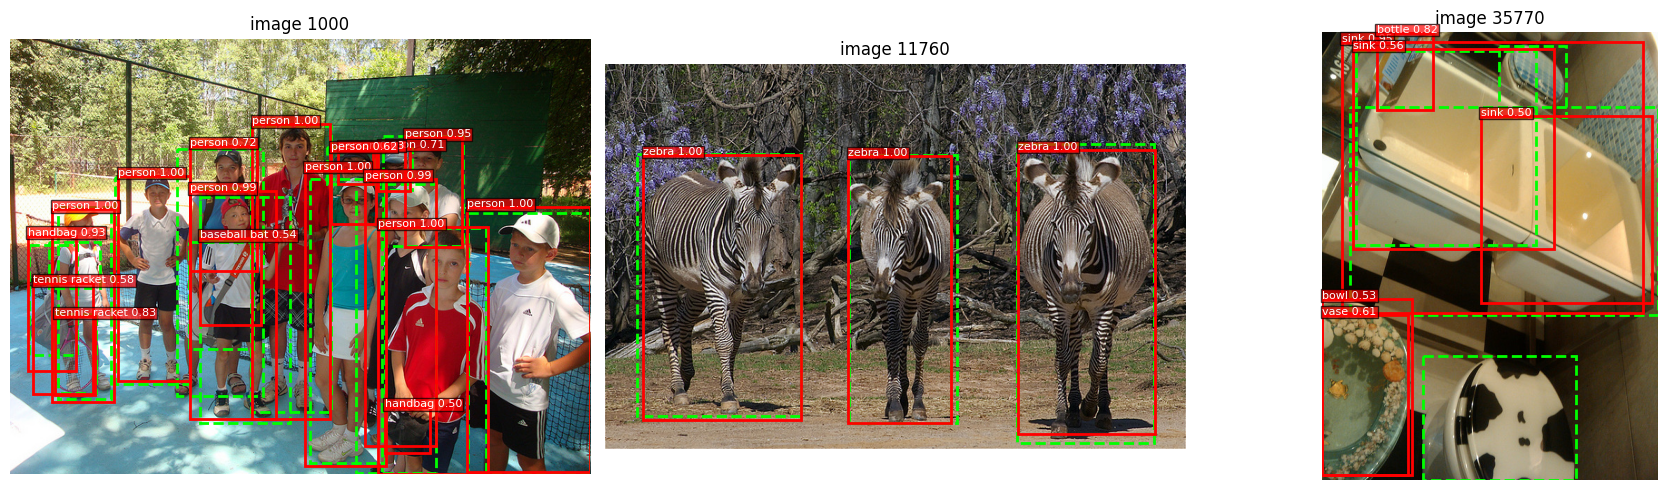

In [10]:
def show_boxes(ids, dets_by_img, thr=0.5):
    """Vérité terrain en vert pointillé, prédictions (score >= thr) en rouge."""
    fig, axes = plt.subplots(1, len(ids), figsize=(6 * len(ids), 5))
    for ax, i in zip(np.atleast_1d(axes), ids):
        ax.imshow(load_img(i)); ax.axis("off"); ax.set_title(f"image {i}")
        for a in gt_img[i]:
            x, y, w, h = a["bbox"]
            ax.add_patch(patches.Rectangle((x, y), w, h, fill=False, ec="lime", lw=2, ls="--"))
        for d in dets_by_img[i]:
            if d["score"] < thr:
                continue
            x, y, w, h = d["bbox"]
            ax.add_patch(patches.Rectangle((x, y), w, h, fill=False, ec="red", lw=2))
            ax.text(x, y, f"{coco.cats[d['category_id']]['name']} {d['score']:.2f}", color="white",
                    fontsize=8, bbox=dict(fc="red", alpha=0.7, pad=1))
    plt.tight_layout(); plt.show()


show_boxes(img_ids[:3], det_by_img)

### 2.1 Évaluation officielle avec `pycocotools`

In [11]:
def coco_eval(results, iou_type):
    dt = coco.loadRes(results)
    E = COCOeval(coco, dt, iou_type)
    E.params.imgIds = img_ids          # on n'évalue que notre sous-ensemble
    E.evaluate(); E.accumulate(); E.summarize()
    return E


STAT_NAMES = ["AP@[.5:.95]", "AP@.5", "AP@.75", "AP small", "AP medium", "AP large"]

E_det = coco_eval(det_results, "bbox")
det_stats = dict(zip(STAT_NAMES, E_det.stats[:6]))
pd.Series(det_stats).round(3).to_frame("Faster R-CNN (bbox)")

Loading and preparing results...
DONE (t=0.32s)
creating index...
index created!
Running per image evaluation...
Evaluate annotation type *bbox*
DONE (t=0.21s).
Accumulating evaluation results...
DONE (t=0.27s).
 Average Precision  (AP) @[ IoU=0.50:0.95 | area=   all | maxDets=100 ] = 0.490
 Average Precision  (AP) @[ IoU=0.50      | area=   all | maxDets=100 ] = 0.717
 Average Precision  (AP) @[ IoU=0.75      | area=   all | maxDets=100 ] = 0.529
 Average Precision  (AP) @[ IoU=0.50:0.95 | area= small | maxDets=100 ] = 0.348
 Average Precision  (AP) @[ IoU=0.50:0.95 | area=medium | maxDets=100 ] = 0.552
 Average Precision  (AP) @[ IoU=0.50:0.95 | area= large | maxDets=100 ] = 0.639
 Average Recall     (AR) @[ IoU=0.50:0.95 | area=   all | maxDets=  1 ] = 0.427
 Average Recall     (AR) @[ IoU=0.50:0.95 | area=   all | maxDets= 10 ] = 0.577
 Average Recall     (AR) @[ IoU=0.50:0.95 | area=   all | maxDets=100 ] = 0.587
 Average Recall     (AR) @[ IoU=0.50:0.95 | area= small | maxDets=10

,Faster R-CNN (bbox)
AP@[.5:.95],0.490
AP@.5,0.717
AP@.75,0.529
AP small,0.348
AP medium,0.552
AP large,0.639


### 2.2 Calcul manuel de l'AP (pour comprendre ce que fait COCO)

AP50 'person' : manuel = 0.844 | pycocotools = 0.845


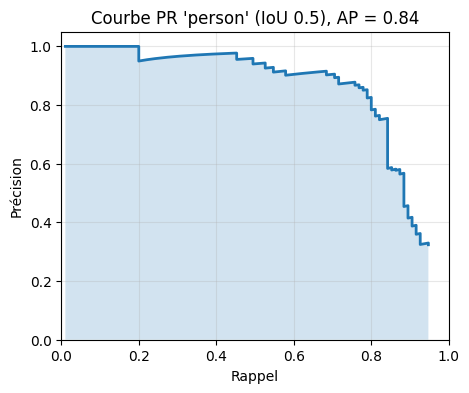

In [12]:
def match_class(dets_by_img, cat_id, iou_thr=0.5):
    """Appariement glouton des prédictions d'une classe. Renvoie (scores, est_TP, nb_GT)."""
    scores, tps, n_gt = [], [], 0
    for img in img_ids:
        g = gt_by[(img, cat_id)]
        n_gt += len(g)
        d = sorted([x for x in dets_by_img[img] if x["category_id"] == cat_id],
                   key=lambda x: -x["score"])
        if not d:
            continue
        used = np.zeros(len(g), dtype=bool)
        if g:
            ious = box_iou_np([[x["bbox"][0], x["bbox"][1], x["bbox"][0] + x["bbox"][2], x["bbox"][1] + x["bbox"][3]] for x in d],
                              [[a["bbox"][0], a["bbox"][1], a["bbox"][0] + a["bbox"][2], a["bbox"][1] + a["bbox"][3]] for a in g])
        for k, x in enumerate(d):
            scores.append(x["score"])
            if not g:
                tps.append(0); continue
            cand = ious[k].copy(); cand[used] = -1
            j = int(cand.argmax())
            if cand[j] >= iou_thr:
                used[j] = True; tps.append(1)
            else:
                tps.append(0)
    return np.array(scores), np.array(tps), n_gt


def average_precision(scores, tps, n_gt):
    """AP = aire sous la courbe PR (précision rendue monotone décroissante)."""
    if n_gt == 0 or len(scores) == 0:
        return 0.0, np.array([0.0]), np.array([0.0])
    order = np.argsort(-scores)
    tp = tps[order]; fp = 1 - tp
    tpc, fpc = np.cumsum(tp), np.cumsum(fp)
    rec = tpc / n_gt
    prec = tpc / np.maximum(tpc + fpc, 1e-9)
    mrec = np.concatenate([[0], rec, [1]])
    mpre = np.concatenate([[0], prec, [0]])
    for k in range(len(mpre) - 2, -1, -1):
        mpre[k] = max(mpre[k], mpre[k + 1])
    idx = np.where(mrec[1:] != mrec[:-1])[0]
    ap = float(np.sum((mrec[idx + 1] - mrec[idx]) * mpre[idx + 1]))
    return ap, rec, prec


# Exemple : classe "person" (id COCO = 1)
s, t, n = match_class(det_by_img, 1, 0.5)
ap_person, rec, prec = average_precision(s, t, n)

# Comparaison avec la valeur calculée par pycocotools (IoU=0.5, toutes tailles, maxDets=100)
k = E_det.params.catIds.index(1)
p = E_det.eval["precision"][0, :, k, 0, 2]
print(f"AP50 'person' : manuel = {ap_person:.3f} | pycocotools = {p[p > -1].mean():.3f}")

plt.figure(figsize=(5, 4))
plt.plot(rec, prec, lw=2)
plt.fill_between(rec, prec, alpha=0.2)
plt.xlabel("Rappel"); plt.ylabel("Précision"); plt.title(f"Courbe PR 'person' (IoU 0.5), AP = {ap_person:.2f}")
plt.xlim(0, 1); plt.ylim(0, 1.05); plt.grid(alpha=0.3); plt.show()

mAP@0.5 manuel (classes présentes dans le sous-ensemble) : 0.715
AP@.5 pycocotools                                       : 0.717
(de petites différences sont normales : interpolation 101 points, classes absentes, objets 'crowd')


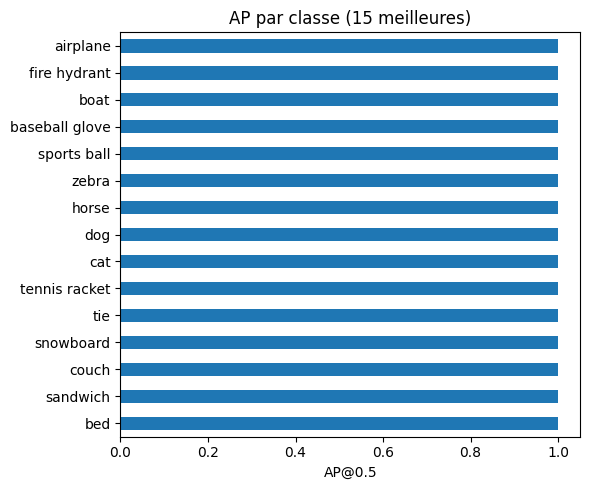

In [13]:
# AP50 par classe et mAP@0.5 manuel
ap_per_class, pooled_scores, pooled_tps, total_gt = {}, [], [], 0
for cat in coco.getCatIds():
    s, t, n = match_class(det_by_img, cat, 0.5)
    if n == 0:
        continue
    ap_per_class[coco.cats[cat]["name"]] = average_precision(s, t, n)[0]
    pooled_scores.append(s); pooled_tps.append(t); total_gt += n

print(f"mAP@0.5 manuel (classes présentes dans le sous-ensemble) : {np.mean(list(ap_per_class.values())):.3f}")
print(f"AP@.5 pycocotools                                       : {det_stats['AP@.5']:.3f}")
print("(de petites différences sont normales : interpolation 101 points, classes absentes, objets 'crowd')")

top = pd.Series(ap_per_class).sort_values(ascending=False)
top.head(15).plot.barh(figsize=(6, 5)).invert_yaxis()
plt.xlabel("AP@0.5"); plt.title("AP par classe (15 meilleures)"); plt.tight_layout(); plt.show()

### 2.3 Choix du seuil de confiance : courbe F1-confiance
L'AP est indépendante du seuil de confiance, mais **en production** il faut en choisir un. On trace précision, rappel et F1 (toutes classes confondues) selon ce seuil.

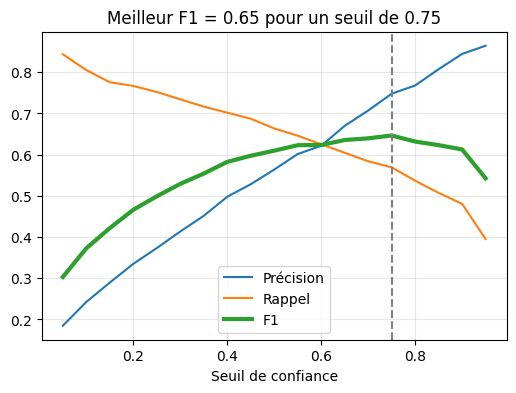

In [14]:
scores_all = np.concatenate(pooled_scores); tps_all = np.concatenate(pooled_tps)
thrs = np.linspace(0.05, 0.95, 19)
P, R, F_scores = [], [], []
for th in thrs:
    keep = scores_all >= th
    tp = int(tps_all[keep].sum()); fp = int(keep.sum() - tp); fn = total_gt - tp
    p_, r_, f_ = prf(tp, fp, fn)
    P.append(p_); R.append(r_); F_scores.append(f_)

best = int(np.argmax(F_scores))
plt.figure(figsize=(6, 4))
plt.plot(thrs, P, label="Précision"); plt.plot(thrs, R, label="Rappel"); plt.plot(thrs, F_scores, label="F1", lw=3)
plt.axvline(thrs[best], ls="--", c="gray")
plt.xlabel("Seuil de confiance"); plt.title(f"Meilleur F1 = {F_scores[best]:.2f} pour un seuil de {thrs[best]:.2f}")
plt.legend(); plt.grid(alpha=0.3); plt.show()

### 2.4 AP selon la taille des objets
Les petits objets sont presque toujours le point faible des détecteurs.

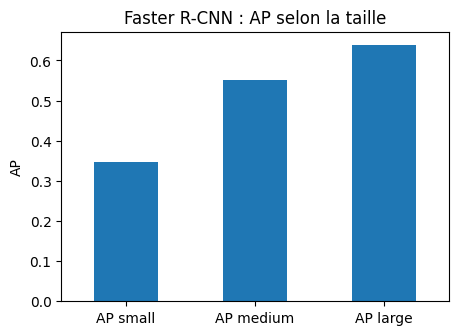

In [15]:
pd.Series({k: det_stats[k] for k in ["AP small", "AP medium", "AP large"]}).plot.bar(figsize=(5, 3.5), rot=0)
plt.ylabel("AP"); plt.title("Faster R-CNN : AP selon la taille"); plt.show()

---
# Section 4 : Évaluation de la segmentation sémantique

**Sortie du modèle :** une **classe par pixel** (pas de notion d'objet individuel).

**Métriques** à partir de la matrice de confusion $C$ (lignes = vérité, colonnes = prédiction) :

$$\text{Pixel acc.}=\frac{\sum_c C_{cc}}{\sum_{c,c'}C_{cc'}}\qquad
\text{IoU}_c=\frac{C_{cc}}{\sum_{c'}C_{cc'}+\sum_{c'}C_{c'c}-C_{cc}}\qquad
\text{mIoU}=\frac1{|\mathcal C|}\sum_c \text{IoU}_c$$

La **pixel accuracy** est trompeuse quand une classe domine (le fond). Le **mIoU** donne le même poids à chaque classe.

**Modèle :** DeepLabV3-ResNet50 de `torchvision`, entraîné sur 20 classes Pascal VOC + fond. On construit donc la vérité terrain sémantique en projetant les masques COCO sur ces 21 classes ; les classes COCO hors VOC comptent comme fond et les zones `crowd` sont ignorées (valeur 255).

In [16]:
from torchvision.models.segmentation import deeplabv3_resnet50, DeepLabV3_ResNet50_Weights

sem_weights = DeepLabV3_ResNet50_Weights.DEFAULT
sem_model = deeplabv3_resnet50(weights=sem_weights).eval().to(DEVICE)
sem_preprocess = sem_weights.transforms()
VOC_CLASSES = sem_weights.meta["categories"]           # 21 classes, 0 = fond
N_CLS = len(VOC_CLASSES)

# Correspondance nom de classe COCO -> indice VOC
COCO2VOC = {"airplane": 1, "bicycle": 2, "bird": 3, "boat": 4, "bottle": 5, "bus": 6, "car": 7,
            "cat": 8, "chair": 9, "cow": 10, "dining table": 11, "dog": 12, "horse": 13,
            "motorcycle": 14, "person": 15, "potted plant": 16, "sheep": 17, "couch": 18,
            "train": 19, "tv": 20}
IGNORE = 255


def build_semantic_gt(img_id):
    info = coco.imgs[img_id]
    gt = np.zeros((info["height"], info["width"]), dtype=np.uint8)
    anns = coco.loadAnns(coco.getAnnIds(imgIds=img_id))
    for a in sorted(anns, key=lambda a: -a["area"]):    # petits objets dessinés par-dessus
        if a["iscrowd"]:
            gt[coco.annToMask(a) > 0] = IGNORE
            continue
        c = COCO2VOC.get(coco.cats[a["category_id"]]["name"])
        if c is not None:
            gt[coco.annToMask(a) > 0] = c
    return gt


@torch.no_grad()
def predict_semantic(img_id):
    img = load_img(img_id)
    out = sem_model(sem_preprocess(img).unsqueeze(0).to(DEVICE))["out"]
    out = torch.nn.functional.interpolate(out, size=(img.height, img.width), mode="bilinear", align_corners=False)
    return out.argmax(1)[0].cpu().numpy().astype(np.uint8)


def confusion(gt, pred, n=N_CLS):
    valid = gt != IGNORE
    return np.bincount(gt[valid].astype(np.int64) * n + pred[valid].astype(np.int64),
                       minlength=n * n).reshape(n, n)


def seg_metrics(cm):
    tp = np.diag(cm).astype(float); gt = cm.sum(1).astype(float); pr = cm.sum(0).astype(float)
    union = gt + pr - tp
    iou = np.where(union > 0, tp / np.maximum(union, 1), np.nan)
    dice = np.where(gt + pr > 0, 2 * tp / np.maximum(gt + pr, 1), np.nan)
    present = gt > 0                                    # classes réellement présentes dans la vérité terrain
    return dict(pixel_acc=tp.sum() / cm.sum(), mIoU=np.nanmean(iou[present]), mDice=np.nanmean(dice[present]),
                fwIoU=np.nansum(gt / gt.sum() * np.nan_to_num(iou)), iou=iou, dice=dice, present=present)

Downloading: "https://download.pytorch.org/models/deeplabv3_resnet50_coco-cd0a2569.pth" to /root/.cache/torch/hub/checkpoints/deeplabv3_resnet50_coco-cd0a2569.pth


100%|██████████| 161M/161M [00:00<00:00, 185MB/s]


In [17]:
sem_gt, sem_pred, sem_img_score = {}, {}, {}
cm_total = np.zeros((N_CLS, N_CLS), dtype=np.int64)

for i in img_ids:
    sem_gt[i] = build_semantic_gt(i)
    sem_pred[i] = predict_semantic(i)
    cm_i = confusion(sem_gt[i], sem_pred[i])
    cm_total += cm_i
    m = seg_metrics(cm_i)
    sem_img_score[i] = float(np.nanmean(m["iou"][m["present"]])) if m["present"].any() else np.nan

sem = seg_metrics(cm_total)
print(f"Pixel accuracy : {sem['pixel_acc']:.3f}")
print(f"mIoU           : {sem['mIoU']:.3f}")
print(f"mDice          : {sem['mDice']:.3f}")
print(f"fwIoU          : {sem['fwIoU']:.3f}")

Pixel accuracy : 0.926
mIoU           : 0.639
mDice          : 0.746
fwIoU          : 0.879


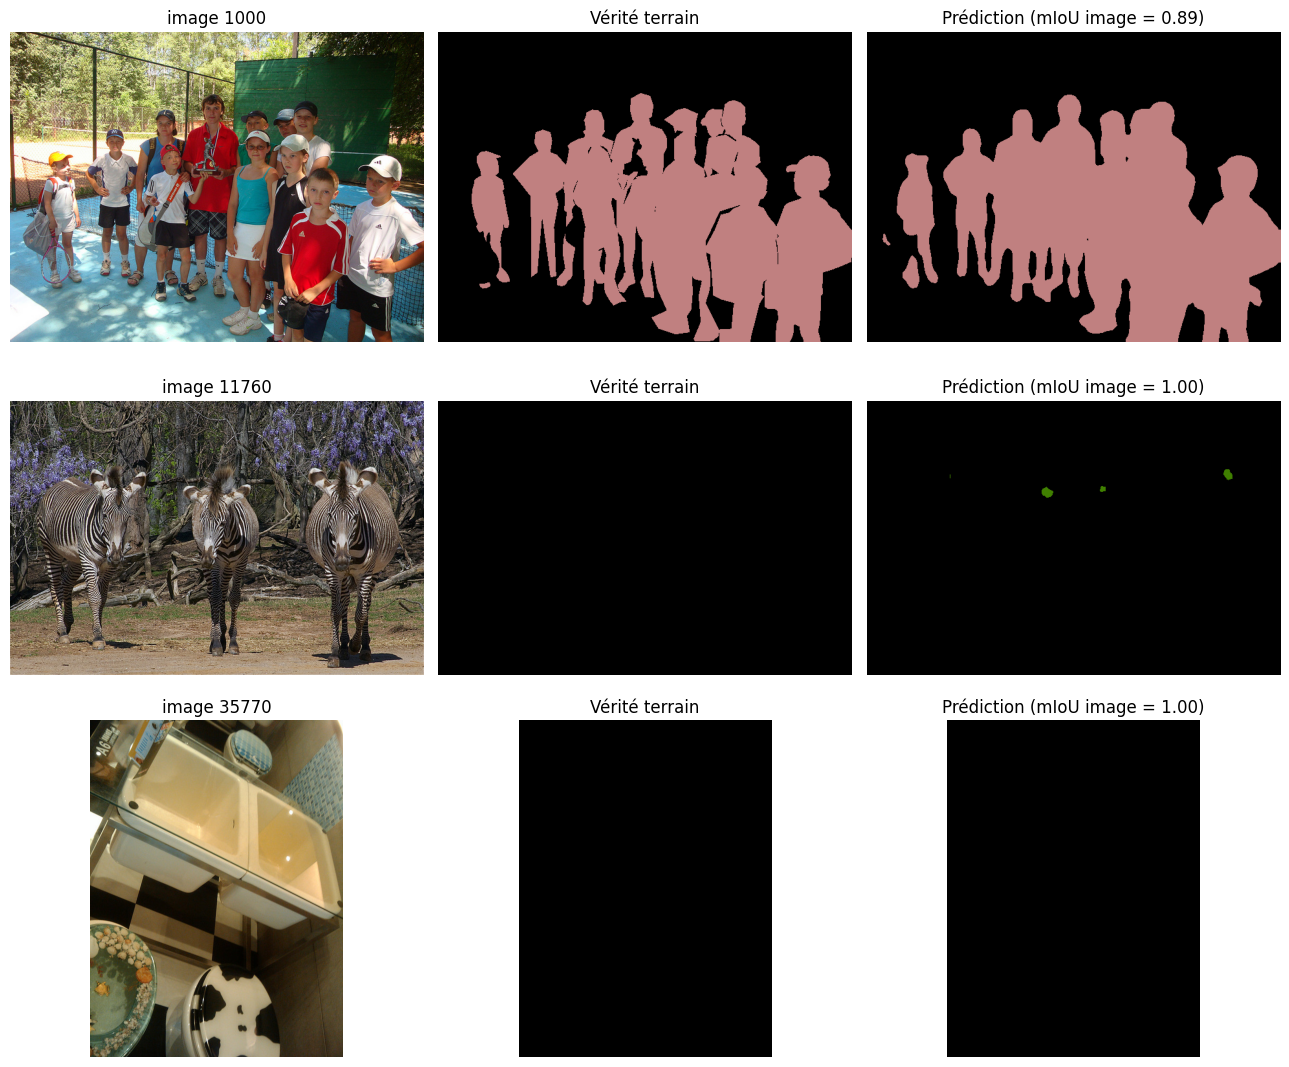

In [18]:
def voc_colormap(N=256):
    cmap = np.zeros((N, 3), dtype=np.uint8)
    for i in range(N):
        c = i; r = g = b = 0
        for j in range(8):
            r |= ((c >> 0) & 1) << (7 - j); g |= ((c >> 1) & 1) << (7 - j); b |= ((c >> 2) & 1) << (7 - j)
            c >>= 3
        cmap[i] = [r, g, b]
    return cmap


CMAP = voc_colormap()


def show_semantic(ids):
    missing = [i for i in ids if i not in sem_gt or i not in sem_pred or i not in sem_img_score]
    if missing:
        raise RuntimeError(f"Résultats sémantiques manquants pour {missing}. Exécutez d'abord entièrement la cellule 23.")
    fig, axes = plt.subplots(len(ids), 3, figsize=(13, 3.6 * len(ids)))
    axes = np.atleast_2d(axes)
    for row, i in zip(axes, ids):
        row[0].imshow(load_img(i)); row[0].set_title(f"image {i}")
        row[1].imshow(CMAP[sem_gt[i]]); row[1].set_title("Vérité terrain")
        row[2].imshow(CMAP[sem_pred[i]])
        row[2].set_title(f"Prédiction (mIoU image = {sem_img_score[i]:.2f})")
        for ax in row: ax.axis("off")
    plt.tight_layout(); plt.show()


show_semantic(img_ids[:3])

### 3.1 IoU par classe

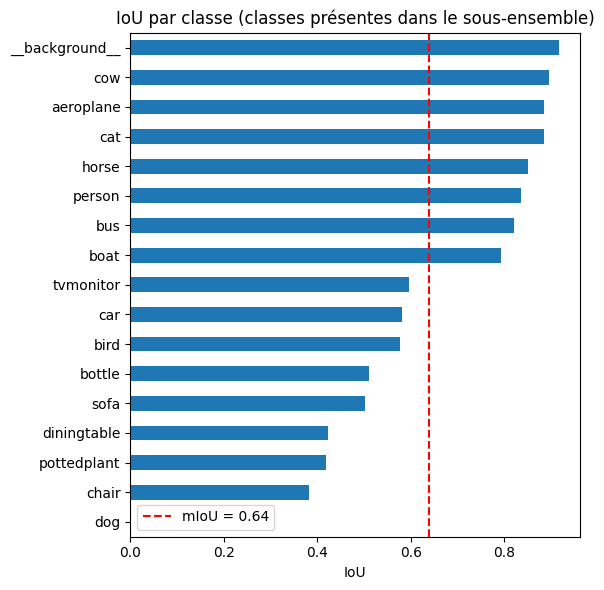

In [19]:
iou_series = pd.Series(sem["iou"], index=VOC_CLASSES)[sem["present"]].sort_values()
iou_series.plot.barh(figsize=(6, 6))
plt.axvline(sem["mIoU"], c="red", ls="--", label=f"mIoU = {sem['mIoU']:.2f}")
plt.xlabel("IoU"); plt.title("IoU par classe (classes présentes dans le sous-ensemble)")
plt.legend(); plt.tight_layout(); plt.show()

### 3.2 Matrice de confusion (normalisée par ligne)
Chaque ligne montre où vont les pixels d'une classe réelle ; les confusions fréquentes (ex. chat/chien, chaise/table) apparaissent hors diagonale.

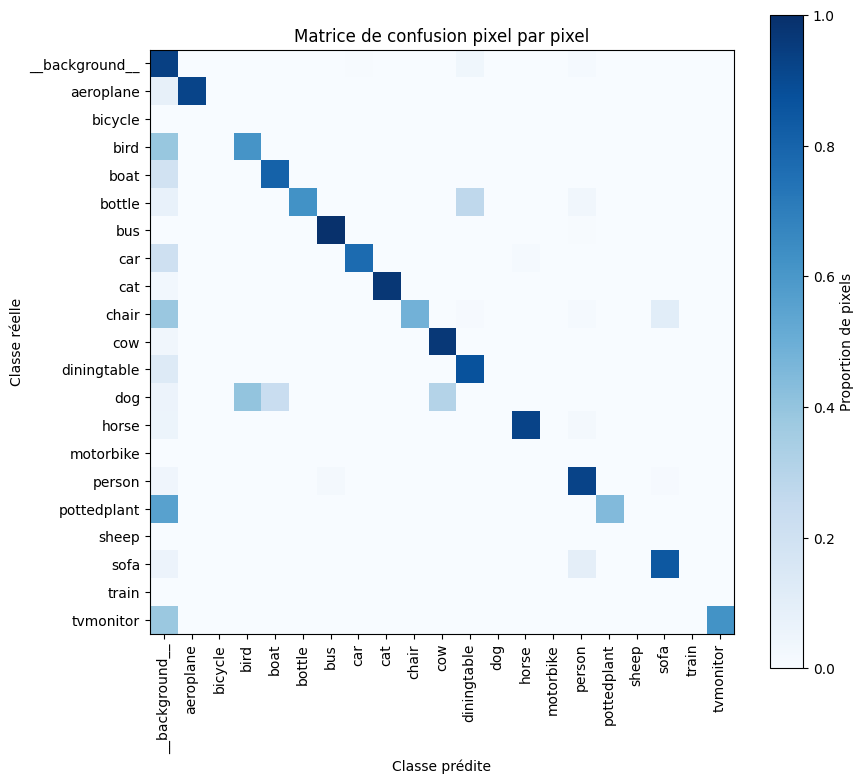

In [20]:
cm_norm = np.divide(cm_total, cm_total.sum(1, keepdims=True), out=np.zeros(cm_total.shape), where=cm_total.sum(1, keepdims=True) > 0)
plt.figure(figsize=(9, 8))
plt.imshow(cm_norm, cmap="Blues", vmin=0, vmax=1)
plt.xticks(range(N_CLS), VOC_CLASSES, rotation=90); plt.yticks(range(N_CLS), VOC_CLASSES)
plt.xlabel("Classe prédite"); plt.ylabel("Classe réelle"); plt.colorbar(label="Proportion de pixels")
plt.title("Matrice de confusion pixel par pixel"); plt.tight_layout(); plt.show()

### 3.3 Le piège de la pixel accuracy
Un « modèle » qui prédit **toujours le fond** obtient une bonne pixel accuracy mais un mIoU quasi nul.

In [21]:
fake_cm = np.zeros_like(cm_total)
fake_cm[:, 0] = cm_total.sum(1)                          # tout est prédit "fond"
base = seg_metrics(fake_cm)

pd.DataFrame({"DeepLabV3": [sem["pixel_acc"], sem["mIoU"]],
              "Toujours 'fond'": [base["pixel_acc"], base["mIoU"]]},
             index=["Pixel accuracy", "mIoU"]).round(3)

,DeepLabV3,Toujours 'fond'
Pixel accuracy,0.926,0.786
mIoU,0.639,0.046


---
# Section 5 : Évaluation de la segmentation d'instances

**Sortie du modèle :** pour chaque objet, un **masque**, une classe et un score. Contrairement à la segmentation sémantique, deux personnes côte à côte sont deux instances distinctes.

**Évaluation :** exactement le même protocole que la détection (AP, mAP@[.5:.95]), mais l'IoU est calculé sur les **masques** et non sur les boîtes :

$$\text{IoU}_{masque}=\frac{|M_{pred}\cap M_{gt}|}{|M_{pred}\cup M_{gt}|}$$

Un masque est plus exigeant qu'une boîte : le **mask AP** est généralement inférieur au **box AP** du même modèle.

*Extension (hors notebook) : la segmentation panoptique unifie les deux mondes avec la métrique PQ = SQ × RQ.*

In [22]:
from torchvision.models.detection import maskrcnn_resnet50_fpn, MaskRCNN_ResNet50_FPN_Weights

inst_model = maskrcnn_resnet50_fpn(weights=MaskRCNN_ResNet50_FPN_Weights.DEFAULT,
                                   box_score_thresh=0.05).eval().to(DEVICE)

inst_segm, inst_bbox = [], []          # mêmes ordre et longueur
inst_by_img = defaultdict(list)        # pour la visualisation
with torch.no_grad():
    for i in img_ids:
        out = inst_model([to_tensor(load_img(i)).to(DEVICE)])[0]
        boxes = out["boxes"].cpu().numpy(); scores = out["scores"].cpu().numpy()
        labels = out["labels"].cpu().numpy(); masks = (out["masks"][:, 0] > 0.5).cpu().numpy()
        for b, s, l, m in zip(boxes, scores, labels, masks):
            rle = mask_util.encode(np.asfortranarray(m.astype(np.uint8)))
            rle["counts"] = rle["counts"].decode("ascii")
            x1, y1, x2, y2 = [float(v) for v in b]
            base = {"image_id": i, "category_id": int(l), "score": float(s)}
            inst_segm.append({**base, "segmentation": rle})
            inst_bbox.append({**base, "bbox": [x1, y1, x2 - x1, y2 - y1]})
            inst_by_img[i].append({**base, "segmentation": rle, "bbox": [x1, y1, x2 - x1, y2 - y1]})

print(len(inst_segm), "instances prédites au total")

Downloading: "https://download.pytorch.org/models/maskrcnn_resnet50_fpn_coco-bf2d0c1e.pth" to /root/.cache/torch/hub/checkpoints/maskrcnn_resnet50_fpn_coco-bf2d0c1e.pth


100%|██████████| 170M/170M [00:00<00:00, 190MB/s]


1605 instances prédites au total


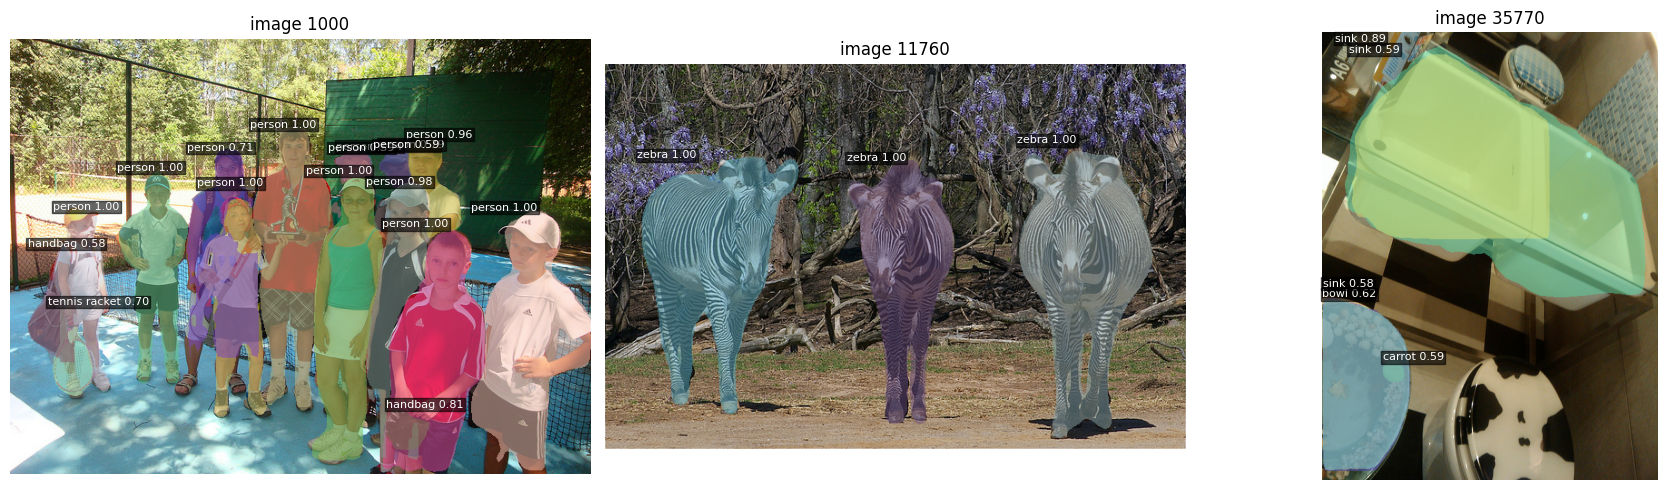

In [23]:
def show_instances(ids, thr=0.5):
    fig, axes = plt.subplots(1, len(ids), figsize=(6 * len(ids), 5))
    rs = np.random.RandomState(1)
    for ax, i in zip(np.atleast_1d(axes), ids):
        canvas = np.array(load_img(i)).astype(np.float32)
        for d in inst_by_img[i]:
            if d["score"] < thr:
                continue
            m = mask_util.decode(d["segmentation"]).astype(bool)
            color = rs.randint(60, 255, 3)
            canvas[m] = 0.5 * canvas[m] + 0.5 * color
        ax.imshow(canvas.astype(np.uint8)); ax.axis("off"); ax.set_title(f"image {i}")
        for d in inst_by_img[i]:
            if d["score"] >= thr:
                x, y, w, h = d["bbox"]
                ax.text(x, y, f"{coco.cats[d['category_id']]['name']} {d['score']:.2f}", color="white",
                        fontsize=8, bbox=dict(fc="black", alpha=0.6, pad=1))
    plt.tight_layout(); plt.show()


show_instances(img_ids[:3])

### 4.1 Mask AP (COCO `segm`) et box AP du même modèle

In [24]:
E_seg = coco_eval(inst_segm, "segm")
E_ibox = coco_eval(inst_bbox, "bbox")

compare = pd.DataFrame({
    "Faster R-CNN (bbox)": E_det.stats[:6],
    "Mask R-CNN (bbox)": E_ibox.stats[:6],
    "Mask R-CNN (segm)": E_seg.stats[:6],
}, index=STAT_NAMES).round(3)
compare

Loading and preparing results...
DONE (t=0.04s)
creating index...
index created!
Running per image evaluation...
Evaluate annotation type *segm*
DONE (t=0.29s).
Accumulating evaluation results...
DONE (t=0.30s).
 Average Precision  (AP) @[ IoU=0.50:0.95 | area=   all | maxDets=100 ] = 0.468
 Average Precision  (AP) @[ IoU=0.50      | area=   all | maxDets=100 ] = 0.672
 Average Precision  (AP) @[ IoU=0.75      | area=   all | maxDets=100 ] = 0.540
 Average Precision  (AP) @[ IoU=0.50:0.95 | area= small | maxDets=100 ] = 0.277
 Average Precision  (AP) @[ IoU=0.50:0.95 | area=medium | maxDets=100 ] = 0.493
 Average Precision  (AP) @[ IoU=0.50:0.95 | area= large | maxDets=100 ] = 0.634
 Average Recall     (AR) @[ IoU=0.50:0.95 | area=   all | maxDets=  1 ] = 0.422
 Average Recall     (AR) @[ IoU=0.50:0.95 | area=   all | maxDets= 10 ] = 0.546
 Average Recall     (AR) @[ IoU=0.50:0.95 | area=   all | maxDets=100 ] = 0.552
 Average Recall     (AR) @[ IoU=0.50:0.95 | area= small | maxDets=10

,Faster R-CNN (bbox),Mask R-CNN (bbox),Mask R-CNN (segm)
AP@[.5:.95],0.490,0.521,0.468
AP@.5,0.717,0.722,0.672
AP@.75,0.529,0.593,0.540
AP small,0.348,0.352,0.277
AP medium,0.552,0.565,0.493
AP large,0.639,0.673,0.634


### 4.2 Pourquoi le mask AP est plus bas : IoU boîte vs IoU masque
Pour chaque instance prédite (score $\geq$ 0.5) on compare l'IoU **masque** et l'IoU **boîte** avec la vérité terrain la plus proche. Les points sous la diagonale sont ceux où la boîte est « meilleure » que le masque.

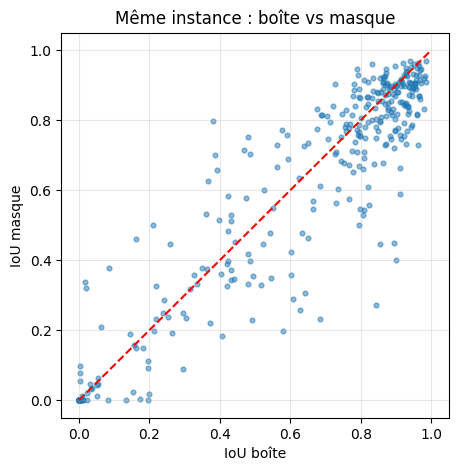

IoU moyen : boîte = 0.635 | masque = 0.606


In [25]:
def xywh2xyxy(b):
    return [b[0], b[1], b[0] + b[2], b[1] + b[3]]


rows = []
for r_seg, r_box in zip(inst_segm, inst_bbox):
    if r_seg["score"] < 0.5:
        continue
    gts = gt_by[(r_seg["image_id"], r_seg["category_id"])]
    if not gts:
        continue
    gt_rles = [coco.annToRLE(a) for a in gts]
    m_ious = mask_util.iou([r_seg["segmentation"]], gt_rles, [0] * len(gts))[0]
    k = int(np.argmax(m_ious))
    b_iou = box_iou_np([xywh2xyxy(r_box["bbox"])], [xywh2xyxy(gts[k]["bbox"])])[0, 0]
    rows.append((float(m_ious[k]), float(b_iou)))

if rows:
    rows = np.asarray(rows, dtype=float)
    plt.figure(figsize=(5, 5))
    plt.scatter(rows[:, 1], rows[:, 0], s=12, alpha=0.5)
    plt.plot([0, 1], [0, 1], "r--")
    plt.xlabel("IoU boîte"); plt.ylabel("IoU masque"); plt.title("Même instance : boîte vs masque")
    plt.grid(alpha=0.3); plt.show()
    print(f"IoU moyen : boîte = {rows[:, 1].mean():.3f} | masque = {rows[:, 0].mean():.3f}")
else:
    print("Aucune instance avec score >= 0.5 et vérité terrain de même classe pour cette comparaison.")

---
# Section 6 : Synthèse

In [26]:
summary = pd.DataFrame([
    ["Classification binaire (illustration)", "Exemple chiffré", "Accuracy", accuracy_bin, "F1", f1_bin],
    ["Classification multi-classe (illustration)", "Exemple chiffré", "Accuracy", accuracy_mc, "F1 macro", macro_mc["F1"]],
    ["Classification multi-label (illustration)", "Exemple chiffré", "F1 micro", micro_f1_ml, "F1 macro", macro_f1_ml],
    ["Détection d'objets", "Faster R-CNN R50-FPN", "mAP@[.5:.95]", det_stats["AP@[.5:.95]"], "mAP@0.5", det_stats["AP@.5"]],
    ["Segmentation sémantique", "DeepLabV3 R50", "mIoU", sem["mIoU"], "Pixel accuracy", sem["pixel_acc"]],
    ["Segmentation d'instances", "Mask R-CNN R50-FPN", "Mask AP@[.5:.95]", E_seg.stats[0], "Mask AP@0.5", E_seg.stats[1]],
], columns=["Tâche", "Modèle / type de résultat", "Métrique principale", "Valeur", "Métrique secondaire", "Valeur secondaire"]).round(3)
summary

,Tâche,Modèle / type de résultat,Métrique principale,Valeur,Métrique secondaire,Valeur secondaire
0,Classification binaire (illustration),Exemple chiffré,Accuracy,0.850,F1,0.842
1,Classification multi-classe (illustration),Exemple chiffré,Accuracy,0.800,F1 macro,0.804
2,Classification multi-label (illustration),Exemple chiffré,F1 micro,0.857,F1 macro,0.667
3,Détection d'objets,Faster R-CNN R50-FPN,mAP@[.5:.95],0.490,mAP@0.5,0.717
4,Segmentation sémantique,DeepLabV3 R50,mIoU,0.639,Pixel accuracy,0.926
5,Segmentation d'instances,Mask R-CNN R50-FPN,Mask AP@[.5:.95],0.468,Mask AP@0.5,0.672


### Cas d'échec : les 3 images les moins bien segmentées (sémantique)

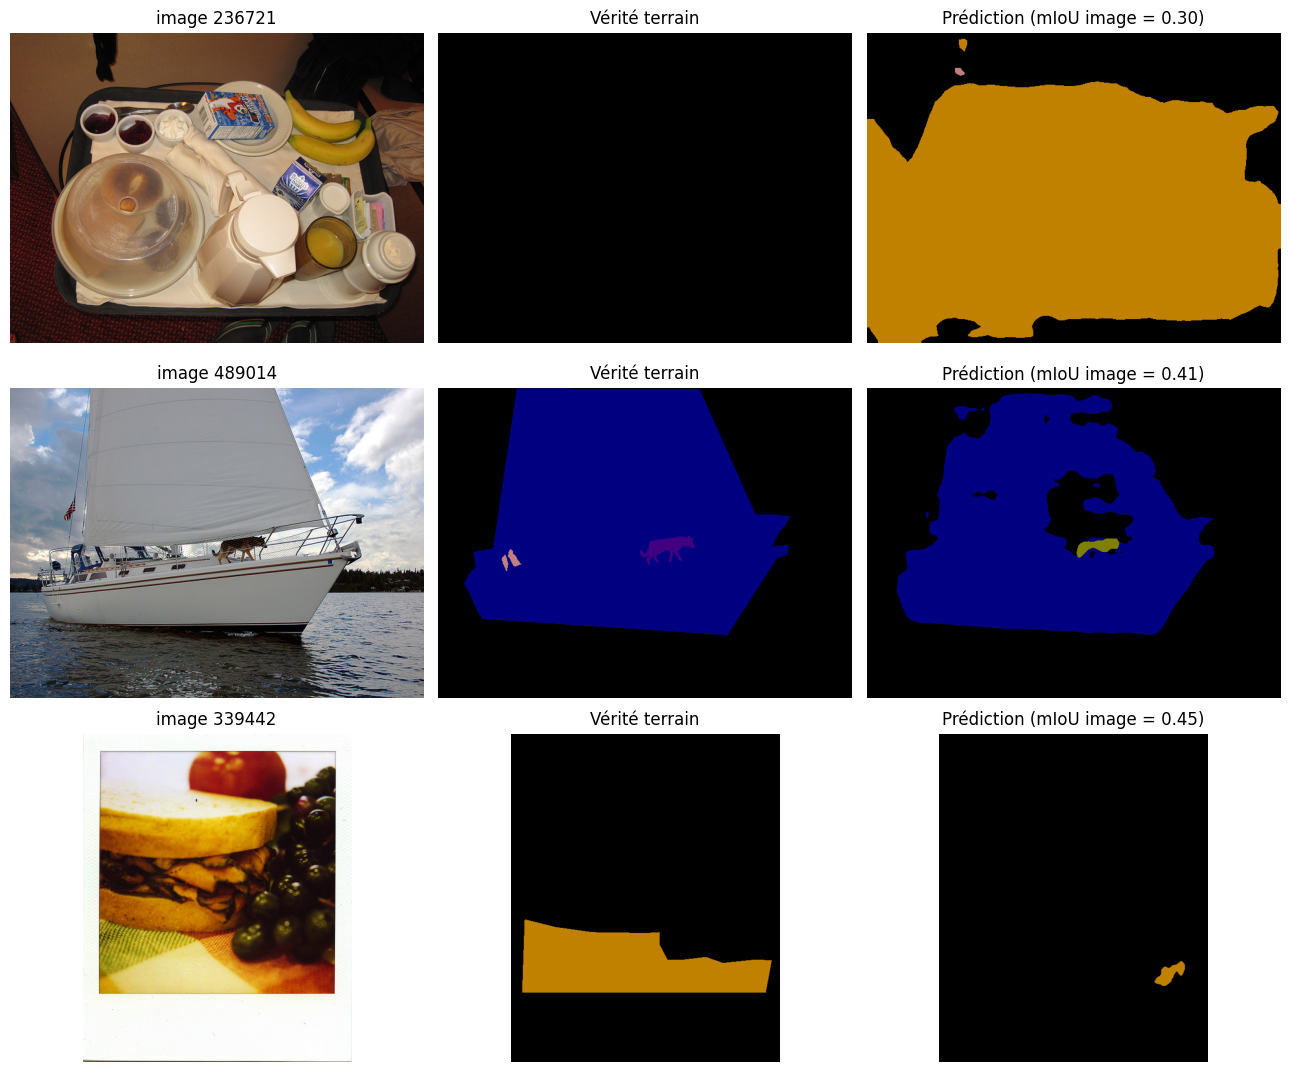

In [27]:
worst = sorted([i for i in img_ids if not np.isnan(sem_img_score[i])], key=lambda i: sem_img_score[i])[:3]
show_semantic(worst)

### Cas d'échec en détection : prédictions très confiantes mais fausses
Boîtes rouges = prédictions (score $\geq$ 0.8), vertes en pointillé = vérité terrain. Cherchez les faux positifs et les objets manqués.

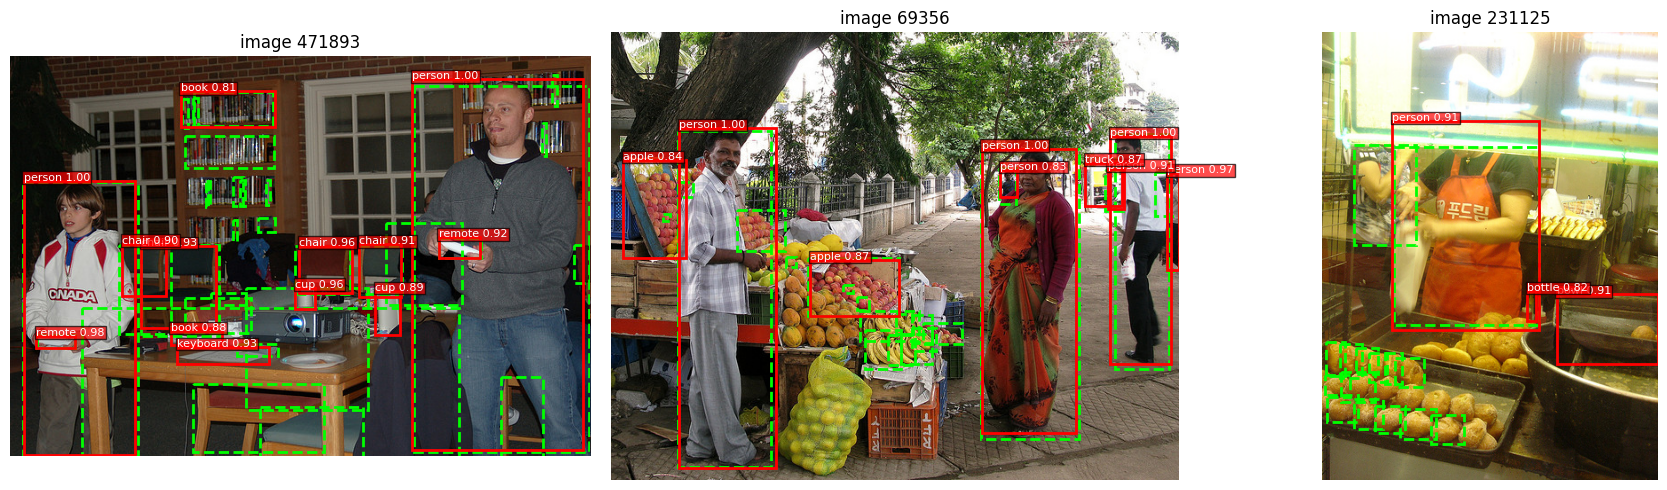

In [28]:
def n_confident(i, thr=0.8):
    return sum(1 for d in det_by_img[i] if d["score"] >= thr)


# Images où le nombre de détections confiantes s'écarte le plus du nombre d'objets annotés
gap = {i: abs(n_confident(i) - len(gt_img[i])) for i in img_ids}
show_boxes(sorted(img_ids, key=lambda i: -gap[i])[:3], det_by_img, thr=0.8)

## Récapitulatif : quelle métrique pour quelle tâche ?

| Tâche | Unité d'évaluation | Métriques clés | Piège principal |
|---|---|---|---|
| Classification binaire | Image | Accuracy, précision, rappel, F1, ROC-AUC | Classes déséquilibrées : accuracy trompeuse |
| Classification multi-classe | Image | Accuracy, Top-k, F1 macro / micro, matrice N×N | Les classes rares peuvent être masquées par la moyenne micro |
| Classification multi-label | Image × étiquette | F1 micro / macro, exact match, Hamming loss, mAP | Exact match très strict ; seuil par étiquette |
| Détection | Objet (boîte) | AP, mAP@0.5, mAP@[.5:.95], AP S/M/L | Choix du seuil de confiance, petits objets |
| Segmentation sémantique | Pixel | mIoU, Dice, pixel acc., matrice de confusion | Pixel accuracy trompeuse (déséquilibre) |
| Segmentation d'instances | Objet (masque) | Mask AP, mAP@[.5:.95] | Plus exigeant que la boîte ; objets qui se chevauchent |

**Note :** les résultats de classification présentés dans la section 2 sont des exemples pédagogiques illustratifs. Les résultats issus de l'expérience COCO concernent la détection et les deux segmentations.

## Bonnes pratiques
- Évaluer sur un jeu **jamais vu** à l'entraînement, avec la **même vérité terrain** pour comparer des modèles.
- Toujours **rapporter plusieurs métriques** (jamais seulement la pixel accuracy ou l'AP@0.5).
- Regarder les **résultats par classe et par taille** : la moyenne cache les faiblesses.
- **Visualiser les erreurs** (faux positifs, objets manqués, confusions de classes) en plus des chiffres.
- Fixer les graines, versions de bibliothèques et protocoles pour la **reproductibilité**.
- Avec 50 images, les chiffres sont **indicatifs** : augmentez `N_IMAGES` pour des conclusions solides.

## Pour aller plus loin
- Segmentation panoptique (PQ, SQ, RQ) · métriques de contour (Boundary F1) · calibration des scores · évaluation sur votre propre jeu de données (format COCO).